# [Lab Session 2](otsu.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**[Task 1.1.]()** Load the image:

In [2]:
imgf = plt.imread('data/NIH3T3/im/dna-0.png')

**[Task 1.2.]()** Quantify the image into 256 bins:

In [3]:
img8 = (imgf * 255).round().astype(np.uint8)

**[Task 1.3.]()** Compute the image histogram:

In [4]:
h = np.zeros(256)
for i in range(256):
    h[i] = (img8 == i).sum()

Show the computed histogram:

<BarContainer object of 256 artists>

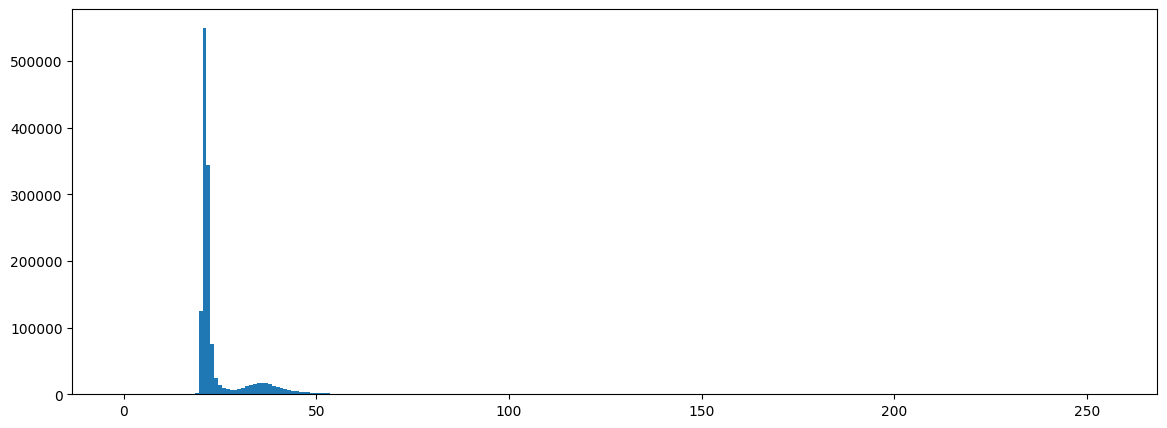

In [7]:
plt.figure(figsize=(14,5))
plt.bar(range(256), h, width=1)

**[Task 1.4.]()** Implement the method of Otsu:

In [9]:
variances = []

for T in range(1, 256):
    class1 = img8[img8 < T]
    class2 = img8[img8 >= T]

    if class1.size == 0 or class2.size == 0:
        variances.append(np.inf)
    else:
        variance = class1.size * np.var(class1) + class2.size * np.var(class2)
        variances.append(variance)

T_star = np.argmin(variances) + 1

print(T_star)

31


In [10]:
print(img8.min())
print(img8.max())
print(np.unique(img8)[:20])

print(variances[:10])
print(min(variances))
print(max(variances))

18
95
[18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37]
[inf, inf, inf, inf, inf, inf, inf, inf, inf, inf]
11275653.93934225
inf


**[Task 1.5.]()** Perform Otsu thresholding:

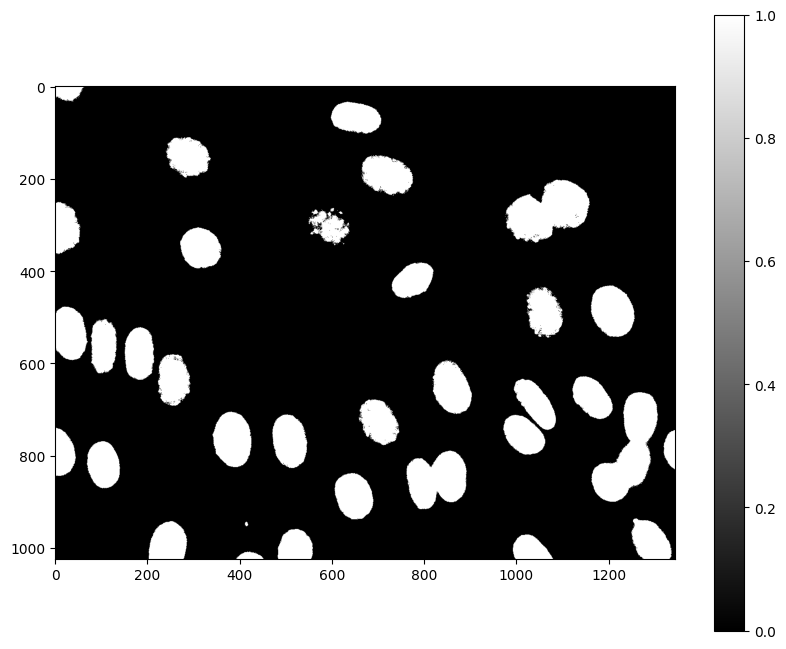

In [11]:
binary_img = img8 >= T_star

plt.figure(figsize=(10, 8))
plt.imshow(binary_img, cmap='gray')
plt.colorbar()
plt.show()

**[Task 1.6.]()** Compute the Dice coefficient:

In [12]:
H = plt.imread('data/NIH3T3/gt/0.png') #ground-truth image

G = binary_img

dice = 2 * (G * H).sum() / (G.sum() + H.sum())

print(dice)

0.8943783223933183
